C:\Users\38098\AppData\Local\Temp\ipykernel_4108\799923383.py:23: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['object']).columns


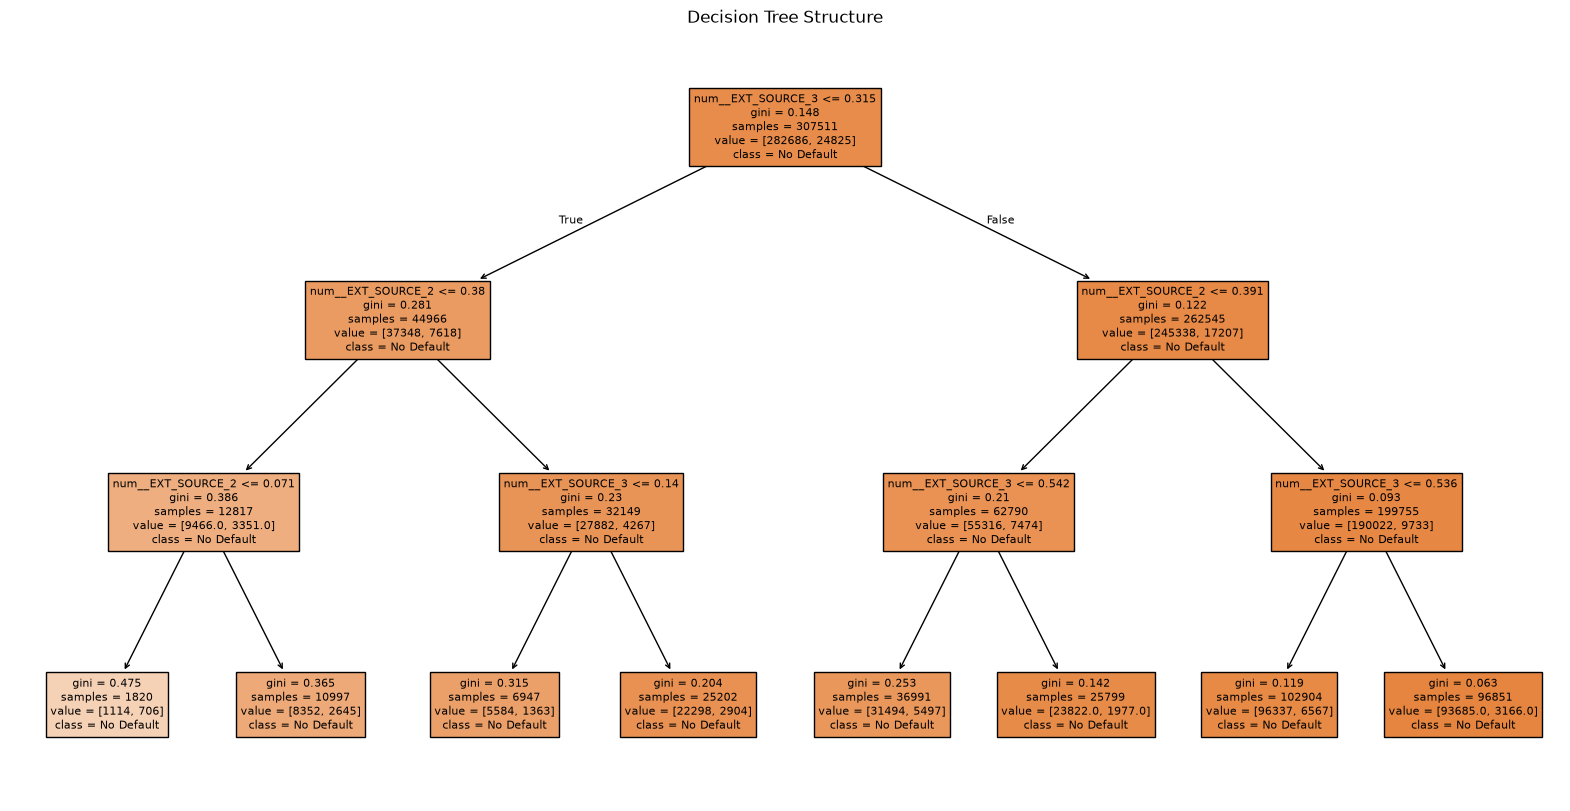

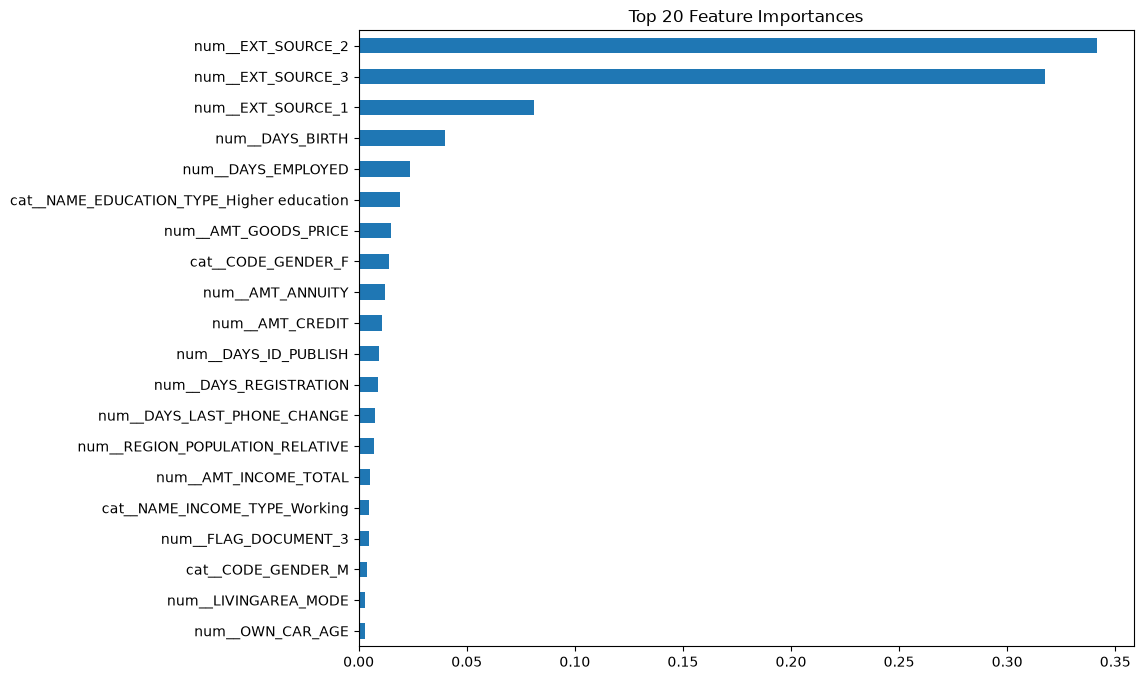

features count:47
Decision Tree (5-Fold CV) ROC-AUC: 0.7155
              precision    recall  f1-score   support

           0       0.96      0.66      0.78    282686
           1       0.15      0.67      0.24     24825

    accuracy                           0.66    307511
   macro avg       0.55      0.66      0.51    307511
weighted avg       0.89      0.66      0.73    307511



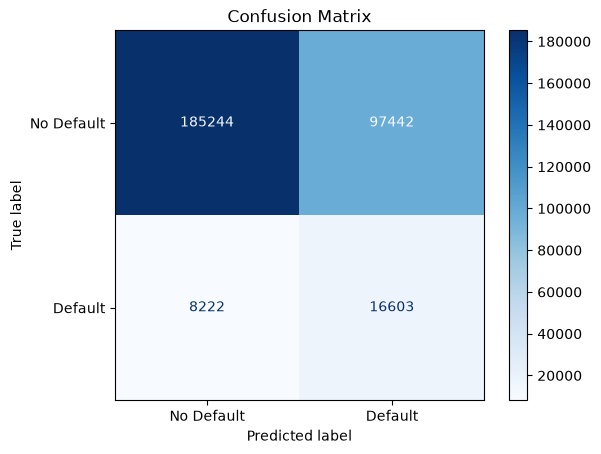

In [2]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

train_df = pd.read_csv('application_train.csv')
test_df = pd.read_csv('application_test.csv')

y = train_df['TARGET']
X = train_df.drop(columns=['TARGET', 'SK_ID_CURR'])
X_test = test_df.drop(columns=['SK_ID_CURR'])
test_ids = test_df['SK_ID_CURR']

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_proc = preprocessor.fit_transform(X)
X_test_proc = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

dt_viz = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_viz.fit(X_proc, y)

plt.figure(figsize=(20, 10))
plot_tree(dt_viz, feature_names=feature_names, class_names=['No Default', 'Default'], filled=True, max_depth=3)
plt.title("Decision Tree Structure")
plt.show()

initial_dt = DecisionTreeClassifier(max_depth=10, min_samples_leaf=100, class_weight='balanced', random_state=42)
initial_dt.fit(X_proc, y)

importances = pd.Series(initial_dt.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
importances.head(20).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title("Top 20 Feature Importances")
plt.show()

top_features_idx = np.where(initial_dt.feature_importances_ > 0.001)[0]
X_proc_sel = X_proc[:, top_features_idx]
X_test_proc_sel = X_test_proc[:, top_features_idx]
print("features count:" + str(len(top_features_idx)))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(X))
test_preds_proba = np.zeros(len(X_test))

for train_idx, val_idx in skf.split(X_proc_sel, y):
    X_tr, y_tr = X_proc_sel[train_idx], y.iloc[train_idx]
    X_va, y_va = X_proc_sel[val_idx], y.iloc[val_idx]
    
    model = DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=100,
        class_weight='balanced',
        random_state=42
    )
    model.fit(X_tr, y_tr)
    
    oof_preds[val_idx] = model.predict_proba(X_va)[:, 1]
    test_preds_proba += model.predict_proba(X_test_proc_sel)[:, 1] / skf.n_splits

print(f"Decision Tree (5-Fold CV) ROC-AUC: {roc_auc_score(y, oof_preds):.4f}")

oof_class_preds = (oof_preds >= 0.5).astype(int)
print(classification_report(y, oof_class_preds))

cm = confusion_matrix(y, oof_class_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Default', 'Default'])
disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix")
plt.show()

submission = pd.DataFrame({
    'SK_ID_CURR': test_ids,
    'TARGET': test_preds_proba
})

submission.to_csv('submission.csv', index=False)